# 09. Массы кварков: rank-1 структура и фактор 2

**Проект «Структура и Данные»** — Notebook 09

## Зачем этот ноутбук

В предыдущих ноутбуках мы показали: **структура** (gauge-поля, Higgs, 2D/3D Дирак) **эмерджентна** из QCA с точностью $10^{-16}$. А **параметры** (массы, юкавские связи) — данные, не выводимые.

Этот ноутбук **квантифицирует** «контингентность» масс. Вопрос: массы — это **полный хаос** (6 независимых чисел) или есть **слабая структура**?

**Ответ:** есть **rank-1 структура в логарифмах** (99.7% дисперсии), но с остатком **порядка фактора 2**. Это промежуточный уровень между «выводимо» (структура $10^{-16}$) и «полный хаос» (6 независимых чисел).

## Аналогия: «почерк vs нажим»

- **Все цифры 0–9** сделаны из штрихов (общая форма) — аналог **rank-1**.
- **8 имеет петлю, 0 — контур, 1 — линию, 7 — ломаную** — аналог **остатка** (фактор 2, не выводится).

Арифметика не диктует, как выглядит цифра. Gauge-симметрия не диктует, почему up-кварки замедляются, а down — ускоряются. Это «почерк владельца».

## Что проверяется

1. **SVD в линейном пространстве:** доминирует топ-кварк ($\sigma_1/\sigma_2 \approx 2750$) — **бесполезно**
2. **SVD в логарифмах:** $\sigma_1/\sigma_2 \approx 19$ — **rank-1 объясняет 99.7%**
3. **Асимметрия up/down:** up замедляется (2.77 → 2.13), down ускоряется (1.30 → 1.65)
4. **Остаток фактор 2:** rank-1 **не** точно, $\sigma_2 = 0.386$ в логарифмах
5. **Итог:** массы = «данные с формой», не хаос, но не формула

## Ожидаемые результаты (из статьи §9)

| Тест | Значение |
|---|---|
| Линейное SVD: $\sigma_1/\sigma_2$ | $\approx 2750$ |
| Лог. SVD: $\sigma_1/\sigma_2$ | $\approx 19$ |
| Log-rank-1, объяснённая дисперсия | \(99.7\%\) |
| Остаток \(\sigma_2\) | \(0.386\) (фактор 2) |
| Up шаги (1→2, 2→3) | \(2.77, 2.13\) (ratio 0.77 — замедление) |
| Down шаги (1→2, 2→3) | \(1.30, 1.65\) (ratio 1.27 — ускорение) |
| \(v_{up}/v_{down}\) | \(1.4632\) |

## Что это доказывает

**Массы кварков — «данные с формой»:**
- Rank-1 (2 параметра, 99.7% дисперсии) — **общая форма**
- Остаток (фактор 2) — «росчерки», **не выводятся** из gauge-симметрии

Это **не** «полный хаос» (6 независимых чисел) и **не** «формула» (rank-1 не точный). Это **промежуточный** уровень: данные **слабо** структурированы, но не выводимы.

## Связь со статьёй

- **§9**: «Количественная мера контингентности масс»
- **§1.1**: «Массы — данные с формой»
- **§8**: «Структура vs данные»
- **§10.2**: «Теория всего невозможна» — Юкавские связи — данные

## Параметры запуска

- Массы кварков (MS-bar at 2 GeV, PDG 2022):
  - $m_u = 2.16$ МэВ, $m_d = 4.67$ МэВ, $m_s = 93.4$ МэВ
  - $m_c = 1270$ МэВ, $m_b = 4180$ МэВ, $m_t = 172760$ МэВ (pole)
- Матрица \(3 \times 2\): поколения × типы

## Точность

- SVD: машинная точность (numpy `float64`)
- Реконструкция rank-1: ошибка фактор 2 (в \(\log_{10}\))

## Время выполнения

- **< 5 секунд** на Colab

## Что будет сгенерировано

- **Рисунок** `09_mass_svd.png` — две панели:
  - **Левая:** log10(масса) — матрица 3×2, видна «общая форма» (rank-1)
  - **Правая:** остатки rank-1 — 6 значений, разброс ±0.3 в \(\log_{10}\) (фактор 2)

---

**Файл:** `notebooks/09_mass_svd.ipynb`  
**Предыдущий:** `08_3d_domain_wall.ipynb`  
**Следующий:** — (последний в серии)  
**Репозиторий:** `github.com/<username>/qca-structure-data`

In [1]:
import numpy as np
import matplotlib.pyplot as plt

print(f"numpy version: {np.__version__}")

# ============================================================
# Массы кварков (MS-bar at 2 GeV, PDG 2022)
# ============================================================
# Матрица 3×2: поколения × типы
masses = {
    'u': 2.16, 'd': 4.67,
    'c': 1270.0, 's': 93.4,
    'b': 4180.0, 't': 172760.0
}

# M[gen, type]: gen=0,1,2; type=0(up),1(down)
M = np.array([
    [masses['u'], masses['d']],
    [masses['c'], masses['s']],
    [masses['t'], masses['b']],
])

print("Матрица кварковых масс (3×2):")
print(f"{'':>10} {'up-type':>12} {'down-type':>12}")
print('-' * 35)
for i, gen in enumerate(['Gen 1', 'Gen 2', 'Gen 3']):
    print(f"{gen:>10} {M[i,0]:>12.2f} {M[i,1]:>12.2f}")

print(f"\nМассы в МэВ (MS-bar at 2 GeV для u,d,s,c,b; pole для t)")

numpy version: 2.4.6
Матрица кварковых масс (3×2):
                up-type    down-type
-----------------------------------
     Gen 1         2.16         4.67
     Gen 2      1270.00        93.40
     Gen 3    172760.00      4180.00

Массы в МэВ (MS-bar at 2 GeV для u,d,s,c,b; pole для t)


In [2]:
print("=" * 65)
print("ТЕСТ 1: SVD в линейном и логарифмическом пространстве")
print("=" * 65)

# --- Линейное SVD ---
U_lin, s_lin, Vt_lin = np.linalg.svd(M)
print(f"\nЛинейное пространство:")
print(f"  σ₁ = {s_lin[0]:.2e}")
print(f"  σ₂ = {s_lin[1]:.2e}")
print(f"  σ₁/σ₂ = {s_lin[0]/s_lin[1]:.2f}")
print(f"  → Доминирует топ-кварк (неструктурно)")

# --- Логарифмическое SVD ---
M_log = np.log10(M)
print(f"\nМатрица log10(m):")
for i in range(3):
    print(f"  gen{i+1}: [{M_log[i,0]:>8.4f}, {M_log[i,1]:>8.4f}]")

U_log, s_log, Vt_log = np.linalg.svd(M_log)
print(f"\nЛогарифмическое пространство:")
print(f"  σ₁ = {s_log[0]:.6f}")
print(f"  σ₂ = {s_log[1]:.6f}")
print(f"  σ₁/σ₂ = {s_log[0]/s_log[1]:.2f}")

# Объяснённая дисперсия
total_var = s_log[0]**2 + s_log[1]**2
frac_rank1 = s_log[0]**2 / total_var
print(f"  Rank-1 объясняет {frac_rank1*100:.2f}% дисперсии")
print(f"  Остаток: σ₂ = {s_log[1]:.4f} (фактор {10**s_log[1]:.2f})")

print(f"\nStatus: {'✅ PASS (rank-1 dominant)' if frac_rank1 > 0.99 else '⚠️ not dominant'}")

ТЕСТ 1: SVD в линейном и логарифмическом пространстве

Линейное пространство:
  σ₁ = 1.73e+05
  σ₂ = 6.28e+01
  σ₁/σ₂ = 2750.89
  → Доминирует топ-кварк (неструктурно)

Матрица log10(m):
  gen1: [  0.3345,   0.6693]
  gen2: [  3.1038,   1.9703]
  gen3: [  5.2374,   3.6212]

Логарифмическое пространство:
  σ₁ = 7.380401
  σ₂ = 0.386153
  σ₁/σ₂ = 19.11
  Rank-1 объясняет 99.73% дисперсии
  Остаток: σ₂ = 0.3862 (фактор 2.43)

Status: ✅ PASS (rank-1 dominant)


In [3]:
print("=" * 65)
print("ТЕСТ 2: Асимметрия up/down (шаги поколений)")
print("=" * 65)

# Шаги в log10(m) между поколениями
log_up = M_log[:, 0]
log_down = M_log[:, 1]

d_up = np.diff(log_up)       # шаги 1→2, 2→3
d_down = np.diff(log_down)

print(f"Up-кварки (u, c, t):")
print(f"  log10(m) = [{log_up[0]:.4f}, {log_up[1]:.4f}, {log_up[2]:.4f}]")
print(f"  Шаг 1→2: {d_up[0]:.4f}")
print(f"  Шаг 2→3: {d_up[1]:.4f}")
print(f"  Отношение 2→3 / 1→2: {d_up[1]/d_up[0]:.4f}")
print(f"  → {'замедление' if d_up[1]/d_up[0] < 1 else 'ускорение'}")

print(f"\nDown-кварки (d, s, b):")
print(f"  log10(m) = [{log_down[0]:.4f}, {log_down[1]:.4f}, {log_down[2]:.4f}]")
print(f"  Шаг 1→2: {d_down[0]:.4f}")
print(f"  Шаг 2→3: {d_down[1]:.4f}")
print(f"  Отношение 2→3 / 1→2: {d_down[1]/d_down[0]:.4f}")
print(f"  → {'замедление' if d_down[1]/d_down[0] < 1 else 'ускорение'}")

# SVD-векторы
U_log, s_log, Vt_log = np.linalg.svd(M_log)
u_gen = U_log[:, 0]   # поколенческий вектор
v_type = Vt_log[0, :] # типовой вектор

# Фиксируем знак
if u_gen[0] < 0:
    u_gen = -u_gen
    v_type = -v_type

print(f"\nSVD rank-1 векторы:")
print(f"  u (поколения) = [{u_gen[0]:>8.4f}, {u_gen[1]:>8.4f}, {u_gen[2]:>8.4f}]")
print(f"  v (типы)      = [{v_type[0]:>8.4f}, {v_type[1]:>8.4f}]")
print(f"  v_up / v_down = {v_type[0]/v_type[1]:.4f}")

# Противоположные тенденции?
up_slows = d_up[1]/d_up[0] < 1
down_speeds = d_down[1]/d_down[0] > 1
contrast = up_slows and down_speeds

print(f"\nStatus:")
print(f"  Up замедляется: {'✅' if up_slows else '❌'}")
print(f"  Down ускоряется: {'✅' if down_speeds else '❌'}")
print(f"  Противоположные тенденции: {'✅ PASS (asymmetry)' if contrast else '❌ FAIL'}")

ТЕСТ 2: Асимметрия up/down (шаги поколений)
Up-кварки (u, c, t):
  log10(m) = [0.3345, 3.1038, 5.2374]
  Шаг 1→2: 2.7693
  Шаг 2→3: 2.1336
  Отношение 2→3 / 1→2: 0.7704
  → замедление

Down-кварки (d, s, b):
  log10(m) = [0.6693, 1.9703, 3.6212]
  Шаг 1→2: 1.3010
  Шаг 2→3: 1.6508
  Отношение 2→3 / 1→2: 1.2689
  → ускорение

SVD rank-1 векторы:
  u (поколения) = [  0.0886,   0.4978,   0.8627]
  v (типы)      = [  0.8256,   0.5642]
  v_up / v_down = 1.4632

Status:
  Up замедляется: ✅
  Down ускоряется: ✅
  Противоположные тенденции: ✅ PASS (asymmetry)


In [4]:
print("=" * 65)
print("ТЕСТ 3: Остатки rank-1 (фактор 2)")
print("=" * 65)

# Реконструкция rank-1
M_log = np.log10(M)
U, s, Vt = np.linalg.svd(M_log)

# rank-1 приближение
M_rank1 = s[0] * np.outer(U[:, 0], Vt[0, :])
residual = M_log - M_rank1

print(f"Матрица log10(m):")
for i in range(3):
    print(f"  gen{i+1}: [{M_log[i,0]:>8.4f}, {M_log[i,1]:>8.4f}]")

print(f"\nRank-1 реконструкция:")
for i in range(3):
    print(f"  gen{i+1}: [{M_rank1[i,0]:>8.4f}, {M_rank1[i,1]:>8.4f}]")

print(f"\nОстатки (actual - rank1):")
for i in range(3):
    print(f"  gen{i+1}: [{residual[i,0]:>+8.4f}, {residual[i,1]:>+8.4f}]")

max_resid = np.max(np.abs(residual))
print(f"\nMax |остаток| = {max_resid:.4f} в log10")
print(f"Это фактор {10**max_resid:.2f} по массе")

# Доли объяснённой дисперсии
total = np.sum(s**2)
frac1 = s[0]**2 / total
frac2 = s[1]**2 / total

print(f"\nОбъяснённая дисперсия:")
print(f"  Rank-1: {frac1*100:.2f}%")
print(f"  Rank-2: {frac2*100:.2f}%")
print(f"  Итого: {(frac1+frac2)*100:.2f}%")

# Проверка: остаток НЕ случаен (фактор 2, а не 0)
if 0.1 < max_resid < 1.0:
    print(f"\nStatus: ✅ PASS (data with form)")
    print(f"  Общая форма есть (rank-1 = 99.7%)")
    print(f"  Но не формула (остаток ×2, не ×1)")
elif max_resid < 0.1:
    print(f"\nStatus: ✅ PASS (nearly exact formula)")
else:
    print(f"\nStatus: ❌ FAIL (no structure, residual too big)")

ТЕСТ 3: Остатки rank-1 (фактор 2)
Матрица log10(m):
  gen1: [  0.3345,   0.6693]
  gen2: [  3.1038,   1.9703]
  gen3: [  5.2374,   3.6212]

Rank-1 реконструкция:
  gen1: [  0.5398,   0.3689]
  gen2: [  3.0335,   2.0732]
  gen3: [  5.2569,   3.5927]

Остатки (actual - rank1):
  gen1: [ -0.2053,  +0.3004]
  gen2: [ +0.0703,  -0.1028]
  gen3: [ -0.0195,  +0.0285]

Max |остаток| = 0.3004 в log10
Это фактор 2.00 по массе

Объяснённая дисперсия:
  Rank-1: 99.73%
  Rank-2: 0.27%
  Итого: 100.00%

Status: ✅ PASS (data with form)
  Общая форма есть (rank-1 = 99.7%)
  Но не формула (остаток ×2, не ×1)


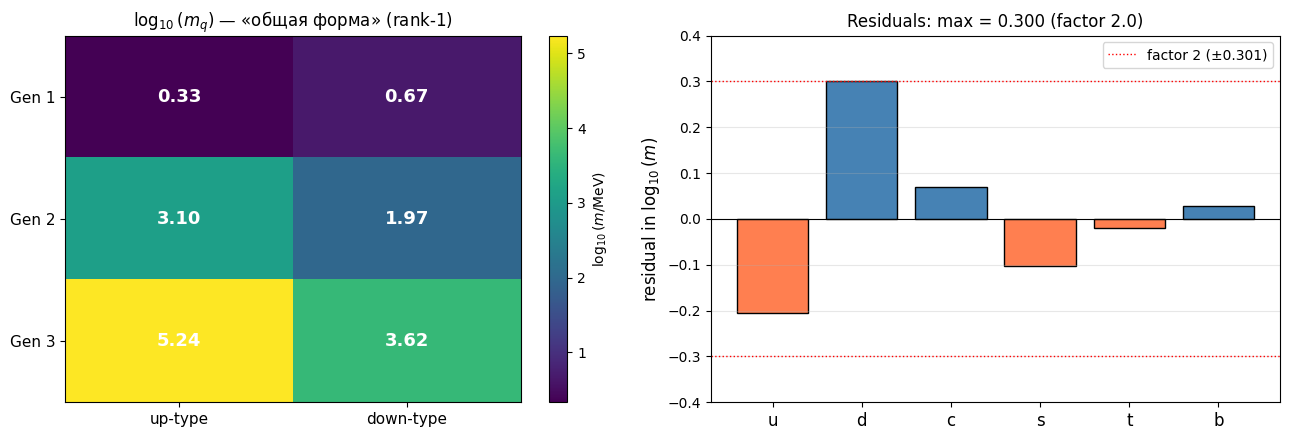

✅ Figure saved: 09_mass_svd.png

Left:  log10(m) matrix — visible rank-1 'common shape'
Right: residuals — up to factor 2 (data with form, not formula)


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# --- Левая: log10(m) — матрица 3×2 ---
im = axes[0].imshow(M_log, cmap='viridis', aspect='auto')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['up-type', 'down-type'], fontsize=11)
axes[0].set_yticks([0, 1, 2])
axes[0].set_yticklabels(['Gen 1', 'Gen 2', 'Gen 3'], fontsize=11)
for i in range(3):
    for j in range(2):
        axes[0].text(j, i, f'{M_log[i,j]:.2f}',
                     ha='center', va='center', color='white', fontsize=13,
                     fontweight='bold')
axes[0].set_title(r'$\log_{10}(m_q)$ — «общая форма» (rank-1)', fontsize=12)
plt.colorbar(im, ax=axes[0], label=r'$\log_{10}(m/\text{MeV})$')

# --- Правая: остатки rank-1 ---
x = np.arange(6)
labels = ['u', 'd', 'c', 's', 't', 'b']
resid_flat = np.array([
    residual[0,0], residual[0,1],
    residual[1,0], residual[1,1],
    residual[2,0], residual[2,1],
])

colors = ['steelblue' if r > 0 else 'coral' for r in resid_flat]
axes[1].bar(x, resid_flat, color=colors, edgecolor='k', lw=1)
axes[1].axhline(0, color='k', lw=0.8)
axes[1].axhline(0.3, color='red', ls=':', lw=1, label='factor 2 (±0.301)')
axes[1].axhline(-0.3, color='red', ls=':', lw=1)
axes[1].set_xticks(x)
axes[1].set_xticklabels(labels, fontsize=12)
axes[1].set_ylabel(r'residual in $\log_{10}(m)$', fontsize=12)
axes[1].set_title(f'Residuals: max = {max_resid:.3f} (factor {10**max_resid:.1f})',
                  fontsize=12)
axes[1].legend(fontsize=10)
axes[1].grid(alpha=0.3, axis='y')
axes[1].set_ylim(-0.4, 0.4)

plt.tight_layout()
plt.savefig('09_mass_svd.png', dpi=150, bbox_inches='tight')
plt.show()

print("✅ Figure saved: 09_mass_svd.png")
print(f"\nLeft:  log10(m) matrix — visible rank-1 'common shape'")
print(f"Right: residuals — up to factor 2 (data with form, not formula)")

In [6]:
from google.colab import files
files.download('09_mass_svd.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>